In [1]:
import pandas as pd
df = pd.read_csv("ab_experiment.csv")

In [14]:
import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']   # Windows 常用
# plt.rcParams['font.sans-serif'] = ['PingFang SC']   # macOS
# plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei']  # Linux
plt.rcParams['axes.unicode_minus'] = False     # 正常显示负号

In [6]:
summary = df.groupby("group")["converted"].agg(["count", "sum", "mean"])
summary.columns = ["users", "converted", "rate"]
summary["se"] = (summary["rate"] * (1 - summary["rate"]) / summary["users"]) ** 0.5
summary["ci_low"] = summary["rate"] - 1.96 * summary["se"]
summary["ci_high"] = summary["rate"] + 1.96 * summary["se"]
print(summary.round(4))

           users  converted    rate      se  ci_low  ci_high
group                                                       
control    10275       1104  0.1074  0.0031  0.1015   0.1134
treatment   9725       1087  0.1118  0.0032  0.1055   0.1180


In [4]:
from statsmodels.stats.proportion import proportions_ztest

ctrl = df[df["group"] == "control"]["converted"]
trt = df[df["group"] == "treatment"]["converted"]

count = [trt.sum(), ctrl.sum()]
nobs = [len(trt), len(ctrl)]
z_stat, p_value = proportions_ztest(count, nobs, alternative="two-sided")
print(f"z = {z_stat:.3f}, p = {p_value:.4f}")

z = 0.980, p = 0.3273


In [5]:
import numpy as np

p_ctrl = ctrl.mean()
p_trt = trt.mean()
abs_lift = p_trt - p_ctrl
rel_lift = abs_lift / p_ctrl

h = 2 * np.arcsin(np.sqrt(p_trt)) - 2 * np.arcsin(np.sqrt(p_ctrl))
print(f"control: {p_ctrl:.4f}, treatment: {p_trt:.4f}")
print(f"绝对提升: {abs_lift*100:.2f} pp, 相对提升: {rel_lift*100:.2f}%")
print(f"Cohen's h: {h:.3f}")

control: 0.1074, treatment: 0.1118
绝对提升: 0.43 pp, 相对提升: 4.03%
Cohen's h: 0.014


In [7]:
se_diff = np.sqrt(p_ctrl*(1-p_ctrl)/len(ctrl) + p_trt*(1-p_trt)/len(trt))
diff = p_trt - p_ctrl
ci_low = diff - 1.96 * se_diff
ci_high = diff + 1.96 * se_diff
print(f"差异 {diff*100:.2f} pp, 95% CI [{ci_low*100:.2f}, {ci_high*100:.2f}] pp")

差异 0.43 pp, 95% CI [-0.43, 1.30] pp


In [8]:
paid = df[df["converted"] == 1]
aov = paid.groupby("group")["amount"].agg(["count", "mean", "std"])
print(aov.round(2))

           count    mean     std
group                           
control     1104  198.10  102.54
treatment   1087  197.26  104.61


In [9]:
from scipy import stats

a_ctrl = paid[paid["group"] == "control"]["amount"]
a_trt = paid[paid["group"] == "treatment"]["amount"]
t_stat, p_t = stats.ttest_ind(a_trt, a_ctrl, equal_var=False)
print(f"t = {t_stat:.3f}, p = {p_t:.4f}")

t = -0.189, p = 0.8501


In [10]:
n1, n2 = len(a_trt), len(a_ctrl)
s_pooled = np.sqrt(((n1-1)*a_trt.std()**2 + (n2-1)*a_ctrl.std()**2) / (n1+n2-2))
d = (a_trt.mean() - a_ctrl.mean()) / s_pooled
print(f"均值差: {a_trt.mean()-a_ctrl.mean():.2f} 元, Cohen's d = {d:.3f}")

均值差: -0.84 元, Cohen's d = -0.008


In [11]:
u_stat, p_u = stats.mannwhitneyu(a_trt, a_ctrl, alternative="two-sided")
print(f"Mann-Whitney p = {p_u:.4f}")

Mann-Whitney p = 0.7914


In [12]:
by_channel = df.groupby(["channel", "group"])["converted"].agg(["count", "mean"]).unstack()
print(by_channel.round(4))

# 分渠道做 z 检验
for ch in df["channel"].unique():
    sub = df[df["channel"] == ch]
    c = sub[sub["group"] == "control"]["converted"]
    t = sub[sub["group"] == "treatment"]["converted"]
    _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
    print(f"{ch}: control {c.mean():.3f}, treatment {t.mean():.3f}, p={p:.4f}, n={len(sub)}")

          count              mean          
group   control treatment control treatment
channel                                    
App        4609      5840  0.1606    0.1421
PC         2009      1451  0.0423    0.0524
小程序        3657      2434  0.0763    0.0744
PC: control 0.042, treatment 0.052, p=0.1653, n=3460
小程序: control 0.076, treatment 0.074, p=0.7802, n=6091
App: control 0.161, treatment 0.142, p=0.0088, n=10449


<Axes: title={'center': '分日转化率'}, xlabel='day_idx'>

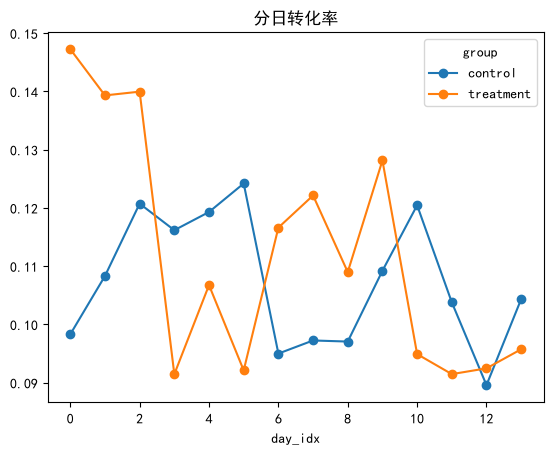

In [15]:
daily = df.groupby(["day_idx", "group"])["converted"].mean().unstack()
daily.plot(marker="o", title="分日转化率")

In [16]:
# D1 / D7 留存率
ret = df.groupby("group")[["active_d1", "active_d7"]].mean()
print(ret.round(4))

# 两比例检验
for col in ["active_d1", "active_d7"]:
    c = df[df["group"] == "control"][col]
    t = df[df["group"] == "treatment"][col]
    _, p = proportions_ztest([t.sum(), c.sum()], [len(t), len(c)])
    print(f"{col}: control {c.mean():.3f}, treatment {t.mean():.3f}, p={p:.4f}")

           active_d1  active_d7
group                          
control       0.3036     0.1485
treatment     0.3200     0.1633
active_d1: control 0.304, treatment 0.320, p=0.0126
active_d7: control 0.149, treatment 0.163, p=0.0040


In [17]:
from statsmodels.stats.multitest import multipletests

p_values = [p_value, p_t, p_d1, p_d7]   # 你所有检验的 p 值
reject, p_adj, _, _ = multipletests(p_values, alpha=0.05, method="bonferroni")
print("校正后 p:", p_adj.round(4))
print("是否显著:", reject)

NameError: name 'p_d1' is not defined